# Tích hợp CLIP và Tip-Adapter (Full Trainval Classification)

Dự án này nghiên cứu và triển khai thuật toán **Tip-Adapter (Training-Free Few-Shot CLIP)** và **Tip-Adapter-F (Fine-Tuned Tip-Adapter)** để phân loại 37 giống chó/mèo từ tập dữ liệu **Oxford-IIIT Pet**.

### 1. Ý tưởng cốt lõi của Tip-Adapter
* **Zero-Shot CLIP:** Phân loại bằng cách so sánh cosine similarity giữa visual feature $F_{test}$ và textual feature $W_{text}$.
* **Tip-Adapter (Training-Free):** Xây dựng một cache key-value từ tập dữ liệu trainval.
  - **Keys ($F_{train}$):** Ảnh train được chuyển đổi qua CLIP Vision Encoder thành visual features.
  - **Values ($L_{train}$):** Nhãn ground-truth của ảnh train được chuyển đổi thành one-hot vectors.
  - **Thu hồi tương đồng (Similarity Retrieval):**
    $$A = \exp(-\beta (1 - F_{test} F_{train}^T))$$
    $$f_{final} = f_{zs} + \alpha \frac{A L_{train}}{N_{train\_per\_class}}$$
  - Ở đây, ta chuẩn hóa quy mô logits của cache bằng cách chia cho số lượng ảnh trung bình trên mỗi lớp ($N_{train\_per\_class}$), giúp cân bằng quy mô giữa Zero-shot logits và Cache logits.
* **Tip-Adapter-F (Fine-Tuned):** Unfreeze (cho phép cập nhật) các trọng số cache keys $W_1 = F_{train}$ trong khi đóng băng các trọng số khác của CLIP và nhãn $W_2 = L_{train}^T$. Mô hình hội tụ rất nhanh chỉ sau vài epochs (20 epochs).

### 2. Thiết lập bài toán (Full Trainval Split)
* Toàn bộ tập dữ liệu **trainval** (3680 ảnh) được chia làm 2 phần:
  - **Train Set (90%):** Dùng làm tập huấn luyện / bộ nhớ cache.
  - **Validation Set (10%):** Dùng để tối ưu tham số và early stopping.
* **Test Set:** Toàn bộ 3,669 ảnh trong tập **test** để làm Query/Test set đánh giá.


In [1]:
import os
import random
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from transformers import CLIPModel, CLIPProcessor
import PIL.Image
from tqdm import tqdm
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Thiết lập thiết bị chạy tự động (MPS cho macOS, CUDA cho GPU, hoặc CPU)
def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    elif torch.backends.mps.is_available():
        return torch.device("mps")
    else:
        return torch.device("cpu")

device = get_device()
print(f"Sử dụng thiết bị phần cứng: {device}")

# Hàm thiết lập seed để đảm bảo tính tái lập kết quả
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


Sử dụng thiết bị phần cứng: mps


In [2]:
class_names = [
    'Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 
    'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair', 'Chihuahua', 'Egyptian Mau', 
    'English Cocker Spaniel', 'English Setter', 'German Shorthaired', 'Great Pyrenees', 
    'Havanese', 'Japanese Chin', 'Keeshond', 'Leonberger', 'Maine Coon', 'Miniature Pinscher', 
    'Newfoundland', 'Persian', 'Pomeranian', 'Pug', 'Ragdoll', 'Russian Blue', 'Saint Bernard', 
    'Samoyed', 'Scottish Terrier', 'Shiba Inu', 'Siamese', 'Sphynx', 'Staffordshire Bull Terrier', 
    'Wheaten Terrier', 'Yorkshire Terrier'
]

class_to_species = {
    # Cats
    'Abyssinian': 'cat', 'Bengal': 'cat', 'Birman': 'cat', 'Bombay': 'cat',
    'British Shorthair': 'cat', 'Egyptian Mau': 'cat', 'Maine Coon': 'cat',
    'Persian': 'cat', 'Ragdoll': 'cat', 'Russian Blue': 'cat', 'Siamese': 'cat',
    'Sphynx': 'cat',
    # Dogs
    'American Bulldog': 'dog', 'American Pit Bull Terrier': 'dog', 'Basset Hound': 'dog',
    'Beagle': 'dog', 'Boxer': 'dog', 'Chihuahua': 'dog', 'English Cocker Spaniel': 'dog', 
    'English Setter': 'dog', 'German Shorthaired': 'dog', 'Great Pyrenees': 'dog',
    'Havanese': 'dog', 'Japanese Chin': 'dog', 'Keeshond': 'dog', 'Leonberger': 'dog',
    'Miniature Pinscher': 'dog', 'Newfoundland': 'dog', 'Pomeranian': 'dog', 'Pug': 'dog',
    'Saint Bernard': 'dog', 'Samoyed': 'dog', 'Scottish Terrier': 'dog', 'Shiba Inu': 'dog',
    'Staffordshire Bull Terrier': 'dog', 'Wheaten Terrier': 'dog', 'Yorkshire Terrier': 'dog',
}


In [3]:
print("Tải CLIP Model và Processor...")
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
model.eval()

# Thiết lập đường dẫn load cache đặc trưng hình ảnh (Sử dụng đường dẫn tương đối ../../dataset)
trainval_features_path = "../../dataset/trainval_features.pt"
trainval_labels_path = "../../dataset/trainval_labels.pt"
test_features_path = "../../dataset/test_features.pt"
test_labels_path = "../../dataset/test_labels.pt"

# Nạp đặc trưng hình ảnh
if (os.path.exists(trainval_features_path) and os.path.exists(trainval_labels_path) and
    os.path.exists(test_features_path) and os.path.exists(test_labels_path)):
    print("Nạp các đặc trưng hình ảnh đã được cache thành công!")
    trainval_features = torch.load(trainval_features_path)
    trainval_labels = torch.load(trainval_labels_path)
    test_features = torch.load(test_features_path)
    test_labels = torch.load(test_labels_path)
    print(f"Kích thước trainval: {trainval_features.shape}")
    print(f"Kích thước test: {test_features.shape}")
else:
    raise FileNotFoundError("Không tìm thấy các file đặc trưng cache trong thư mục dataset/! Vui lòng chạy file extract_features.py trước.")


Tải CLIP Model và Processor...
Nạp các đặc trưng hình ảnh đã được cache thành công!
Kích thước trainval: torch.Size([3680, 512])
Kích thước test: torch.Size([3669, 512])


In [4]:
# Trích xuất và chuẩn hoá L2 đặc trưng của nhãn văn bản
# 1. Bare class names (Zero-shot baseline)
with torch.no_grad():
    inputs_bare = processor(text=class_names, return_tensors="pt", padding=True).to(device)
    text_features_bare = model.get_text_features(**inputs_bare)
    text_features_bare = text_features_bare / text_features_bare.norm(dim=-1, keepdim=True)
    
# 2. Enriched prompts (Prompt Engineering)
prompts_enriched = [f"Picture of a pet with breed: {c}, which is a type of {class_to_species.get(c)}" for c in class_names]
with torch.no_grad():
    inputs_enriched = processor(text=prompts_enriched, return_tensors="pt", padding=True).to(device)
    text_features_enriched = model.get_text_features(**inputs_enriched)
    text_features_enriched = text_features_enriched / text_features_enriched.norm(dim=-1, keepdim=True)

print("Kích thước đặc trưng văn bản bare:", text_features_bare.shape)
print("Kích thước đặc trưng văn bản prompt enriched:", text_features_enriched.shape)


Kích thước đặc trưng văn bản bare: torch.Size([37, 512])
Kích thước đặc trưng văn bản prompt enriched: torch.Size([37, 512])


In [5]:
# Hàm phân chia trainval thành 90% train và 10% validation theo phân tầng (stratified)
def get_train_val_split(features, labels, train_ratio=0.9, seed=42):
    set_seed(seed)
    num_classes = 37
    train_idx = []
    val_idx = []
    
    for c in range(num_classes):
        class_indices = (labels == c).nonzero(as_tuple=True)[0]
        shuffled = class_indices[torch.randperm(len(class_indices))]
        
        split_point = int(len(class_indices) * train_ratio)
        train_idx.append(shuffled[:split_point])
        val_idx.append(shuffled[split_point:])
        
    train_idx = torch.cat(train_idx)
    val_idx = torch.cat(val_idx)
    
    return features[train_idx], labels[train_idx], features[val_idx], labels[val_idx]

train_features, train_labels, val_features, val_labels = get_train_val_split(
    trainval_features, trainval_labels, train_ratio=0.9, seed=42
)
print("Kích thước tập Train (90%):", train_features.shape)
print("Kích thước tập Validation (10%):", val_features.shape)


Kích thước tập Train (90%): torch.Size([3310, 512])
Kích thước tập Validation (10%): torch.Size([370, 512])


In [6]:
# Đánh giá độ chính xác Zero-Shot
def evaluate_zero_shot(test_feats, test_lbls, text_feats):
    sim = test_feats.to(device) @ text_feats.to(device).t()
    preds = sim.argmax(dim=-1)
    acc = (preds == test_lbls.to(device)).float().mean().item()
    return acc * 100

acc_zs_bare = evaluate_zero_shot(test_features, test_labels, text_features_bare)
acc_zs_enriched = evaluate_zero_shot(test_features, test_labels, text_features_enriched)

print(f"1. Độ chính xác Zero-Shot (Bare class name): {acc_zs_bare:.2f}%")
print(f"2. Độ chính xác Zero-Shot (Prompt Engineering): {acc_zs_enriched:.2f}%")


1. Độ chính xác Zero-Shot (Bare class name): 80.16%
2. Độ chính xác Zero-Shot (Prompt Engineering): 88.44%


In [7]:
# Triển khai Tip-Adapter (Training-Free)
def run_tip_adapter(test_feats, text_feats, support_feats, support_lbls, alpha, beta):
    logits_zs = test_feats.to(device) @ text_feats.to(device).t()
    
    # Cache similarity
    sim_matrix = test_feats.to(device) @ support_feats.to(device).t() # (N, M)
    A = torch.exp(-beta * (1.0 - sim_matrix))
    
    # One-hot labels
    L_support = F.one_hot(support_lbls.to(device), num_classes=37).float()
    
    # Tính số lượng ảnh trung bình mỗi lớp trong support set để làm nhân tử chuẩn hoá
    # K_avg = M / 37
    K_avg = len(support_feats) / 37.0
    
    # Logits_final = logits_zs + alpha * (A @ L_support) / K_avg
    logits_final = logits_zs + alpha * (A @ L_support) / K_avg
    return logits_final

# Tìm kiếm tham số alpha & beta tốt nhất trên tập Validation
def grid_search_tip_adapter(val_feats, val_lbls, text_feats, support_feats, support_lbls):
    alphas = [0.1, 0.5, 1.0, 1.5, 2.0, 3.0, 5.0]
    betas = [1.0, 2.0, 3.0, 5.0, 10.0]
    
    best_acc = 0.0
    best_alpha = 1.0
    best_beta = 1.0
    
    for alpha in alphas:
        for beta in betas:
            logits_val = run_tip_adapter(val_feats, text_feats, support_feats, support_lbls, alpha, beta)
            preds = logits_val.argmax(dim=-1)
            acc = (preds == val_lbls.to(device)).float().mean().item()
            if acc > best_acc:
                best_acc = acc
                best_alpha = alpha
                best_beta = beta
                
    return best_alpha, best_beta


In [8]:
# Triển khai Tip-Adapter-F (Fine-Tuned)
class TipAdapterF(nn.Module):
    def __init__(self, support_features, support_labels, text_features, beta, alpha):
        super().__init__()
        # Trọng số W1 là Key cache (có thể huấn luyện)
        self.W_1 = nn.Parameter(support_features.clone())
        
        # Trọng số W2 là Value cache (nhãn one-hot cố định)
        L_support = F.one_hot(support_labels, num_classes=37).float()
        self.register_buffer("W_2", L_support)
        
        # Đặc trưng prompt text cố định
        self.register_buffer("W_text", text_features.clone())
        
        self.beta = beta
        self.alpha = alpha
        # Lưu số ảnh trung bình làm nhân tử chuẩn hoá
        self.register_buffer("K_avg", torch.tensor(len(support_features) / 37.0))
        
    def forward(self, F_x):
        # Zero-shot logits
        logits_zs = F_x @ self.W_text.t()
        
        # Chuẩn hoá đặc trưng W_1
        W_1_norm = self.W_1 / self.W_1.norm(dim=-1, keepdim=True)
        
        # Cache similarity
        sim_matrix = F_x @ W_1_norm.t()
        A = torch.exp(-self.beta * (1.0 - sim_matrix))
        
        # Kết hợp các logits dự đoán
        logits_final = logits_zs + self.alpha * (A @ self.W_2) / self.K_avg
        return logits_final

# Huấn luyện Tip-Adapter-F
def train_tip_adapter_f(support_feats, support_lbls, val_feats, val_lbls, text_feats, beta, alpha, epochs=20, lr=0.001):
    model_f = TipAdapterF(support_feats, support_lbls, text_feats, beta, alpha).to(device)
    
    # Chỉ tối ưu W_1
    optimizer = torch.optim.SGD([model_f.W_1], lr=lr, momentum=0.9, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()
    
    dataset = TensorDataset(support_feats, support_lbls)
    batch_size = min(256, len(support_feats))
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    
    best_val_acc = 0.0
    best_W_1 = None
    
    for epoch in range(epochs):
        model_f.train()
        for x_batch, y_batch in loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
            
            optimizer.zero_grad()
            outputs = model_f(x_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            
        # Đánh giá sớm trên tập Validation
        model_f.eval()
        with torch.no_grad():
            val_outputs = model_f(val_feats.to(device))
            val_preds = val_outputs.argmax(dim=-1)
            val_acc = (val_preds == val_lbls.to(device)).float().mean().item()
            
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_W_1 = model_f.W_1.clone()
            
    # Load trọng số tốt nhất đạt được
    if best_W_1 is not None:
        with torch.no_grad():
            model_f.W_1.copy_(best_W_1)
            
    return model_f


In [9]:
# Chạy Grid Search và huấn luyện Tip-Adapter
print("1. Tìm kiếm siêu tham số tối ưu trên Validation set...")
alpha, beta = grid_search_tip_adapter(
    val_features, val_labels, text_features_enriched, train_features, train_labels
)
print(f"-> Tham số tối ưu tìm được: alpha={alpha}, beta={beta}")

print("\n2. Chạy đánh giá Tip-Adapter (Free) trên tập Test...")
logits_test_free = run_tip_adapter(
    test_features, text_features_enriched, train_features, train_labels, alpha, beta
)
preds_free = logits_test_free.argmax(dim=-1)
acc_free = (preds_free == test_labels.to(device)).float().mean().item() * 100
print(f"-> Độ chính xác Tip-Adapter (Free): {acc_free:.2f}%")

print("\n3. Huấn luyện Tip-Adapter-F (Tuned) trên tập Train trong 20 epochs...")
model_f = train_tip_adapter_f(
    train_features, train_labels, val_features, val_labels, text_features_enriched, beta, alpha, epochs=20, lr=0.001
)
model_f.eval()
with torch.no_grad():
    logits_test_tuned = model_f(test_features.to(device))
    preds_tuned = logits_test_tuned.argmax(dim=-1)
    acc_tuned = (preds_tuned == test_labels.to(device)).float().mean().item() * 100
print(f"-> Độ chính xác Tip-Adapter-F (Tuned): {acc_tuned:.2f}%")


1. Tìm kiếm siêu tham số tối ưu trên Validation set...
-> Tham số tối ưu tìm được: alpha=0.5, beta=10.0

2. Chạy đánh giá Tip-Adapter (Free) trên tập Test...
-> Độ chính xác Tip-Adapter (Free): 89.13%

3. Huấn luyện Tip-Adapter-F (Tuned) trên tập Train trong 20 epochs...
-> Độ chính xác Tip-Adapter-F (Tuned): 89.13%


TÓM TẮT ĐỘ CHÍNH XÁC PHÂN LOẠI:
--------------------------------------------------
CLIP Zero-Shot (Bare):           80.16%
CLIP Zero-Shot (Prompt Eng):     88.44%
Tip-Adapter (Free, Full Train):  89.13%
Tip-Adapter-F (Tuned, Full):     89.13%
--------------------------------------------------


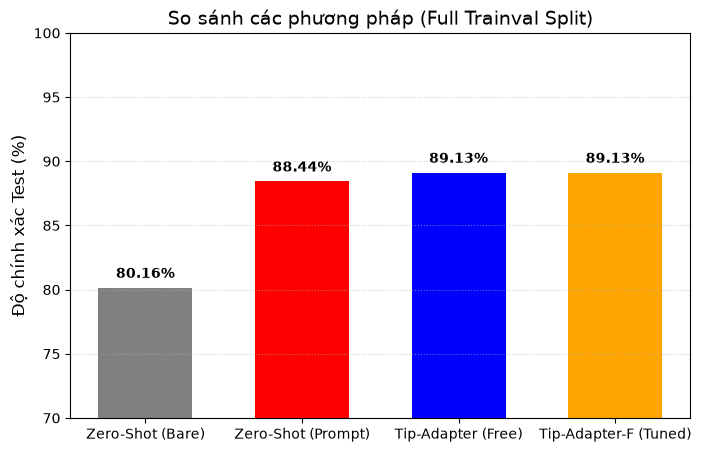

In [10]:
# Báo cáo kết quả bằng bảng
print("TÓM TẮT ĐỘ CHÍNH XÁC PHÂN LOẠI:")
print("-" * 50)
print(f"CLIP Zero-Shot (Bare):           {acc_zs_bare:.2f}%")
print(f"CLIP Zero-Shot (Prompt Eng):     {acc_zs_enriched:.2f}%")
print(f"Tip-Adapter (Free, Full Train):  {acc_free:.2f}%")
print(f"Tip-Adapter-F (Tuned, Full):     {acc_tuned:.2f}%")
print("-" * 50)

# Trực quan hoá kết quả bằng biểu đồ cột
methods = ['Zero-Shot (Bare)', 'Zero-Shot (Prompt)', 'Tip-Adapter (Free)', 'Tip-Adapter-F (Tuned)']
accuracies = [acc_zs_bare, acc_zs_enriched, acc_free, acc_tuned]

plt.figure(figsize=(8, 5))
bars = plt.bar(methods, accuracies, color=['gray', 'red', 'blue', 'orange'], width=0.6)
plt.title('So sánh các phương pháp (Full Trainval Split)', fontsize=14)
plt.ylabel('Độ chính xác Test (%)', fontsize=12)
plt.ylim(70, 100)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.savefig('clip_tip_adapter_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


In [11]:
# Đo độ trễ suy diễn (Inference Latency)
print("Đang thực hiện đo đạc Latency...")

model.to(device)
latencies = []
for i in range(100):
    start = time.perf_counter()
    with torch.no_grad():
        test_img = test_features[i:i+1].to(device)
        logits = test_img @ text_features_enriched.to(device).t()
        preds = logits.argmax(dim=-1)
    end = time.perf_counter()
    latencies.append((end - start) * 1000)

print(f"Thiết bị: {device}")
print(f"  Trung bình (Mean): {np.mean(latencies):.4f} ms")
print(f"  Phân vị p50 (Median): {np.percentile(latencies, 50):.4f} ms")
print(f"  Phân vị p95: {np.percentile(latencies, 95):.4f} ms")
print(f"  Phân vị p99: {np.percentile(latencies, 99):.4f} ms")

latencies_cpu = []
test_features_cpu = test_features.cpu()
text_features_cpu = text_features_enriched.cpu()
for i in range(100):
    start = time.perf_counter()
    with torch.no_grad():
        test_img = test_features_cpu[i:i+1]
        logits = test_img @ text_features_cpu.t()
        preds = logits.argmax(dim=-1)
    end = time.perf_counter()
    latencies_cpu.append((end - start) * 1000)

print(f"Thiết bị: CPU")
print(f"  Trung bình (Mean): {np.mean(latencies_cpu):.4f} ms")
print(f"  Phân vị p50 (Median): {np.percentile(latencies_cpu, 50):.4f} ms")
print(f"  Phân vị p95: {np.percentile(latencies_cpu, 95):.4f} ms")
print(f"  Phân vị p99: {np.percentile(latencies_cpu, 99):.4f} ms")


Đang thực hiện đo đạc Latency...
Thiết bị: mps
  Trung bình (Mean): 2.1712 ms
  Phân vị p50 (Median): 0.2897 ms
  Phân vị p95: 1.0541 ms
  Phân vị p99: 2.9380 ms
Thiết bị: CPU
  Trung bình (Mean): 0.0166 ms
  Phân vị p50 (Median): 0.0057 ms
  Phân vị p95: 0.0078 ms
  Phân vị p99: 0.0284 ms


Tạo Ma Trận Nhầm Lẫn cho mô hình Tip-Adapter-F...


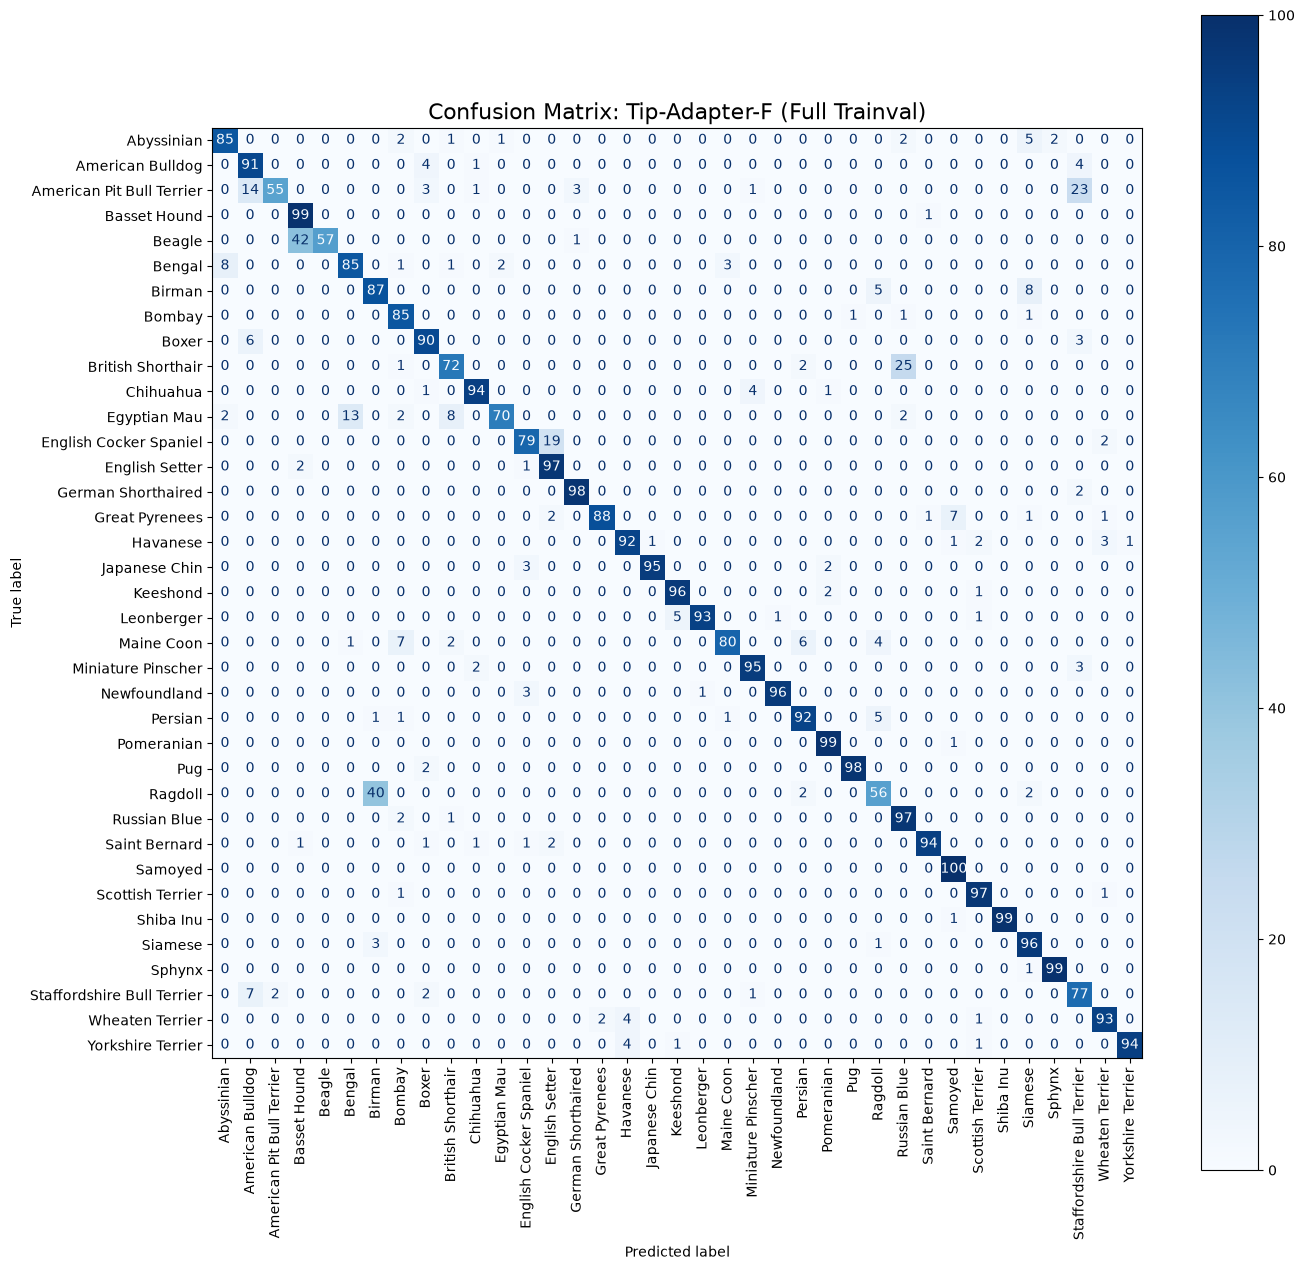

In [12]:
# Tạo ma trận nhầm lẫn
print("Tạo Ma Trận Nhầm Lẫn cho mô hình Tip-Adapter-F...")
cm = confusion_matrix(test_labels.numpy(), preds_tuned.cpu().numpy())

fig, ax = plt.subplots(figsize=(15, 15))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap='Blues', xticks_rotation='vertical')
plt.title("Confusion Matrix: Tip-Adapter-F (Full Trainval)", fontsize=16)
plt.savefig('confusion_matrix_16shot.png', bbox_inches='tight', dpi=300)
plt.show()


In [13]:
# Lưu kết quả
import json
os.makedirs("results", exist_ok=True)

summary_data = {
    "zs_bare": acc_zs_bare,
    "zs_enriched": acc_zs_enriched,
    "tip_free": acc_free,
    "tip_tuned": acc_tuned,
    "latency_device": {
        "device": str(device),
        "mean": float(np.mean(latencies)),
        "p50": float(np.percentile(latencies, 50)),
        "p95": float(np.percentile(latencies, 95)),
        "p99": float(np.percentile(latencies, 99))
    }
}

with open("results/summary_results.json", "w") as f:
    json.dump(summary_data, f, indent=4)
    
print("Lưu file kết quả thành công tại results/summary_results.json!")


Lưu file kết quả thành công tại results/summary_results.json!
